
Input: `outputs/step2_prepared.joblib`.
Output: `outputs/step3_models.joblib` (trained models) and `outputs/training_results.csv`.

In [ ]:
# Working folder: holds HABs_ScrippsPier_v3.xlsx and the outputs/ folder shared by all steps.
# In Colab the folder is on Google Drive, so every step notebook can read what the previous step saved.
import os
WORK_FOLDER = "/content/drive/MyDrive/BIF633_Progress2"
try:
    from google.colab import drive
    drive.mount("/content/drive")
    os.makedirs(WORK_FOLDER, exist_ok=True)
    os.chdir(WORK_FOLDER)
except ImportError:
    pass  # not running in Colab: use the current folder
os.makedirs("outputs", exist_ok=True)
print("Working folder:", os.getcwd())

In [ ]:
# Load everything saved by the previous step
import joblib
globals().update(joblib.load("outputs/step2_prepared.joblib"))
print("Loaded outputs/step2_prepared.joblib")

In [ ]:
#Step 7 Model training

In [ ]:
X_train_C = processed_feature_sets["C_Full_Temporal"]["X_train"]
X_validation_C = processed_feature_sets["C_Full_Temporal"]["X_validation"]
X_test_C = processed_feature_sets["C_Full_Temporal"]["X_test"]

In [ ]:
# ============================================================
# STEP 7.1 — MODEL TRAINING SETUP
# ============================================================

import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR

from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score,
    mean_absolute_percentage_error
)

warnings.filterwarnings("ignore")


# Check that Step 6 was completed
required_objects = [
    "processed_feature_sets",
    "y_train",
    "y_validation",
    "y_test"
]

missing_objects = [
    name for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise NameError(
        "Please run Steps 4–6 first. "
        f"Missing objects: {missing_objects}"
    )


print("Available processed feature sets:")

for set_name, result in processed_feature_sets.items():
    print(
        f"- {set_name}: "
        f"{len(result['features'])} predictors"
    )

print("\nTarget sizes:")
print("Training:", len(y_train))
print("Validation:", len(y_validation))
print("Test:", len(y_test))

Available processed feature sets:
- A_Environmental: 6 predictors
- B_Environmental_Seasonal: 8 predictors
- C_Full_Temporal: 15 predictors
- C_Linear_Selected: 13 predictors

Target sizes:
Training: 361
Validation: 77
Test: 78


In [ ]:
# ============================================================
# STEP 7.2 — EVALUATION FUNCTIONS
# ============================================================

def convert_log_prediction_to_original(y_log):
    """
    Convert log1p predictions back to the original Chl-a scale.
    Negative values after inverse transformation are clipped to zero.
    """

    y_original = np.expm1(np.asarray(y_log))

    return np.clip(
        y_original,
        a_min=0,
        a_max=None
    )


def calculate_regression_metrics(
    y_true_log,
    y_pred_log
):
    """
    Calculate metrics on both log scale and original Chl-a scale.
    """

    y_true_log = np.asarray(y_true_log)
    y_pred_log = np.asarray(y_pred_log)

    y_true_original = convert_log_prediction_to_original(
        y_true_log
    )

    y_pred_original = convert_log_prediction_to_original(
        y_pred_log
    )

    # Avoid division by zero when calculating MAPE
    nonzero_mask = y_true_original > 0

    if nonzero_mask.sum() > 0:
        mape = mean_absolute_percentage_error(
            y_true_original[nonzero_mask],
            y_pred_original[nonzero_mask]
        ) * 100
    else:
        mape = np.nan

    return {
        "RMSE_log": np.sqrt(
            mean_squared_error(
                y_true_log,
                y_pred_log
            )
        ),

        "MAE_log": mean_absolute_error(
            y_true_log,
            y_pred_log
        ),

        "RMSE_original": np.sqrt(
            mean_squared_error(
                y_true_original,
                y_pred_original
            )
        ),

        "MAE_original": mean_absolute_error(
            y_true_original,
            y_pred_original
        ),

        "R2_original": r2_score(
            y_true_original,
            y_pred_original
        ),

        "MAPE_percent": mape
    }


print("Evaluation functions are ready.")

Evaluation functions are ready.


In [ ]:
# ============================================================
# STEP 7.3 — TIME-SERIES CROSS-VALIDATION
# ============================================================

number_of_splits = 5

time_series_cv = TimeSeriesSplit(
    n_splits=number_of_splits
)

cv_summary = []

for fold_number, (train_index, cv_index) in enumerate(
    time_series_cv.split(
        processed_feature_sets[
            "C_Full_Temporal"
        ]["X_train"]
    ),
    start=1
):
    cv_summary.append({
        "Fold": fold_number,
        "Training_observations": len(train_index),
        "CV_observations": len(cv_index),
        "Training_start_index": train_index[0],
        "Training_end_index": train_index[-1],
        "CV_start_index": cv_index[0],
        "CV_end_index": cv_index[-1]
    })


cv_summary = pd.DataFrame(cv_summary)
display(cv_summary)

,Fold,Training_observations,CV_observations,Training_start_index,Training_end_index,CV_start_index,CV_end_index
0,1,61,60,0,60,61,120
1,2,121,60,0,120,121,180
2,3,181,60,0,180,181,240
3,4,241,60,0,240,241,300
4,5,301,60,0,300,301,360


In [ ]:
# ============================================================
# STEP 7.4 — MODELS AND HYPERPARAMETER GRIDS
# ============================================================

model_configurations = {
    "Linear Regression": {
        "model": LinearRegression(),
        "parameters": {
            "fit_intercept": [True, False]
        }
    },

    "Ridge Regression": {
        "model": Ridge(),
        "parameters": {
            "alpha": [0.01, 0.1, 1.0, 10.0, 100.0]
        }
    },

    "Random Forest": {
        "model": RandomForestRegressor(
            random_state=42,
            n_jobs=-1
        ),
        "parameters": {
            "n_estimators": [200, 500],
            "max_depth": [None, 5, 10],
            "min_samples_split": [2, 5],
            "min_samples_leaf": [1, 3],
            "max_features": ["sqrt", 0.7]
        }
    },

    "SVR": {
        "model": SVR(kernel="rbf"),
        "parameters": {
            "C": [0.1, 1, 10, 100],
            "epsilon": [0.01, 0.1, 0.2],
            "gamma": ["scale", 0.01, 0.1, 1.0]
        }
    }
}


for model_name, configuration in model_configurations.items():

    number_of_combinations = int(
        np.prod([
            len(values)
            for values in configuration[
                "parameters"
            ].values()
        ])
    )

    print(
        f"{model_name}: "
        f"{number_of_combinations} parameter combinations"
    )

Linear Regression: 2 parameter combinations
Ridge Regression: 5 parameter combinations
Random Forest: 48 parameter combinations
SVR: 48 parameter combinations


In [ ]:
# ============================================================
# STEP 7.5 — MODEL–FEATURE SET COMBINATIONS
# ============================================================

training_plan = [
    # Linear models
    ("Linear Regression", "A_Environmental"),
    ("Linear Regression", "B_Environmental_Seasonal"),
    ("Linear Regression", "C_Linear_Selected"),

    ("Ridge Regression", "A_Environmental"),
    ("Ridge Regression", "B_Environmental_Seasonal"),
    ("Ridge Regression", "C_Full_Temporal"),

    # Random Forest
    ("Random Forest", "A_Environmental"),
    ("Random Forest", "B_Environmental_Seasonal"),
    ("Random Forest", "C_Full_Temporal"),

    # SVR
    ("SVR", "A_Environmental"),
    ("SVR", "B_Environmental_Seasonal"),
    ("SVR", "C_Full_Temporal")
]


# Keep only combinations whose feature sets exist
training_plan = [
    (model_name, feature_set_name)
    for model_name, feature_set_name in training_plan
    if feature_set_name in processed_feature_sets
]


training_plan_table = pd.DataFrame(
    training_plan,
    columns=["Model", "Feature_set"]
)

display(training_plan_table)

print(
    "Total model–feature combinations:",
    len(training_plan)
)

,Model,Feature_set
0,Linear Regression,A_Environmental
1,Linear Regression,B_Environmental_Seasonal
2,Linear Regression,C_Linear_Selected
3,Ridge Regression,A_Environmental
4,Ridge Regression,B_Environmental_Seasonal
5,Ridge Regression,C_Full_Temporal
6,Random Forest,A_Environmental
7,Random Forest,B_Environmental_Seasonal
8,Random Forest,C_Full_Temporal
9,SVR,A_Environmental


Total model–feature combinations: 12


In [ ]:
# ============================================================
# STEP 7.6 — TRAIN AND TUNE ALL MODELS
# Training set: GridSearchCV + TimeSeriesSplit
# Validation set: Compare model performance
# Test set: Not used in this step
# ============================================================

# Reset previous incomplete results
trained_models = {}
training_results = []

total_start_time = time.time()


for run_number, (
    model_name,
    feature_set_name
) in enumerate(training_plan, start=1):

    print("\n" + "=" * 70)
    print(
        f"Run {run_number}/{len(training_plan)}"
    )
    print("Model:", model_name)
    print("Feature set:", feature_set_name)
    print("=" * 70)

    run_start_time = time.time()

    # --------------------------------------------------------
    # 1. Retrieve processed Training and Validation data
    # --------------------------------------------------------

    X_train_model = processed_feature_sets[
        feature_set_name
    ]["X_train"]

    X_validation_model = processed_feature_sets[
        feature_set_name
    ]["X_validation"]

    print("Training shape:", X_train_model.shape)
    print(
        "Validation shape:",
        X_validation_model.shape
    )

    # --------------------------------------------------------
    # 2. Retrieve model and hyperparameter grid
    # --------------------------------------------------------

    base_model = clone(
        model_configurations[model_name]["model"]
    )

    parameter_grid = model_configurations[
        model_name
    ]["parameters"]

    # --------------------------------------------------------
    # 3. Configure GridSearchCV
    # --------------------------------------------------------

    grid_search = GridSearchCV(
        estimator=base_model,
        param_grid=parameter_grid,

        # Minimize RMSE on log-transformed target
        scoring="neg_root_mean_squared_error",

        # Preserve chronological order within Training set
        cv=time_series_cv,

        # Use available CPU cores
        n_jobs=-1,

        # Refit the best model on the complete Training set
        refit=True,

        return_train_score=False,
        error_score="raise"
    )

    # --------------------------------------------------------
    # 4. Train and tune using Training set only
    # --------------------------------------------------------

    grid_search.fit(
        X_train_model,
        y_train
    )

    # --------------------------------------------------------
    # 5. Predict the Validation set
    # --------------------------------------------------------

    validation_prediction_log = (
        grid_search.best_estimator_.predict(
            X_validation_model
        )
    )

    # --------------------------------------------------------
    # 6. Calculate Validation metrics
    # --------------------------------------------------------

    validation_metrics = calculate_regression_metrics(
        y_true_log=y_validation,
        y_pred_log=validation_prediction_log
    )

    elapsed_seconds = (
        time.time() - run_start_time
    )

    # Unique identifier for each model–feature combination
    model_key = (
        f"{model_name}__{feature_set_name}"
    )

    # --------------------------------------------------------
    # 7. Store fitted model and related information
    # --------------------------------------------------------

    trained_models[model_key] = {
        "model_name": model_name,
        "feature_set_name": feature_set_name,

        "features": processed_feature_sets[
            feature_set_name
        ]["features"],

        "best_estimator": (
            grid_search.best_estimator_
        ),

        "best_parameters": (
            grid_search.best_params_
        ),

        "best_cv_RMSE_log": (
            -grid_search.best_score_
        ),

        "validation_prediction_log": (
            validation_prediction_log
        ),

        "grid_search": grid_search
    }

    # --------------------------------------------------------
    # 8. Store one comparison-table row
    # --------------------------------------------------------

    result_row = {
        "Model_key": model_key,
        "Model": model_name,
        "Feature_set": feature_set_name,

        "Number_of_features": (
            X_train_model.shape[1]
        ),

        "CV_RMSE_log": (
            -grid_search.best_score_
        ),

        "RMSE_log": (
            validation_metrics["RMSE_log"]
        ),

        "MAE_log": (
            validation_metrics["MAE_log"]
        ),

        "RMSE_original": (
            validation_metrics["RMSE_original"]
        ),

        "MAE_original": (
            validation_metrics["MAE_original"]
        ),

        "R2_original": (
            validation_metrics["R2_original"]
        ),

        "MAPE_percent": (
            validation_metrics["MAPE_percent"]
        ),

        "Training_time_seconds": (
            elapsed_seconds
        ),

        "Best_parameters": str(
            grid_search.best_params_
        )
    }

    training_results.append(result_row)

    # Create an updated checkpoint table after every run
    training_results_checkpoint = pd.DataFrame(
        training_results
    )

    # --------------------------------------------------------
    # 9. Display current-run results
    # --------------------------------------------------------

    print("\nBest parameters:")
    print(grid_search.best_params_)

    print(
        "\nCross-validation RMSE (log scale):",
        round(
            -grid_search.best_score_,
            4
        )
    )

    print(
        "Validation RMSE (log scale):",
        round(
            validation_metrics["RMSE_log"],
            4
        )
    )

    print(
        "Validation RMSE (original scale):",
        round(
            validation_metrics["RMSE_original"],
            4
        )
    )

    print(
        "Validation MAE (original scale):",
        round(
            validation_metrics["MAE_original"],
            4
        )
    )

    print(
        "Validation R²:",
        round(
            validation_metrics["R2_original"],
            4
        )
    )

    print(
        "Validation MAPE:",
        round(
            validation_metrics["MAPE_percent"],
            2
        ),
        "%"
    )

    print(
        "Elapsed time:",
        round(elapsed_seconds, 1),
        "seconds"
    )


# ============================================================
# CREATE FINAL STEP 7 RESULTS TABLE
# ============================================================

training_results_df = pd.DataFrame(
    training_results
)

training_results_df = training_results_df.sort_values(
    by=[
        "RMSE_original",
        "MAE_original"
    ],
    ascending=[
        True,
        True
    ]
).reset_index(drop=True)


total_elapsed_minutes = (
    time.time() - total_start_time
) / 60


print("\n" + "=" * 70)
print("STEP 7.6 TRAINING COMPLETED")
print("=" * 70)

print(
    "Completed model–feature combinations:",
    len(training_results_df)
)

print(
    "Total training time:",
    round(total_elapsed_minutes, 2),
    "minutes"
)

print(
    "\nModels are ranked using Validation RMSE "
    "on the original Chl-a scale."
)

display(training_results_df)


Run 1/12
Model: Linear Regression
Feature set: A_Environmental
Training shape: (361, 6)
Validation shape: (77, 6)

Best parameters:
{'fit_intercept': True}

Cross-validation RMSE (log scale): 0.6862
Validation RMSE (log scale): 0.5836
Validation RMSE (original scale): 4.1078
Validation MAE (original scale): 2.2103
Validation R²: -0.0444
Validation MAPE: 49.15 %
Elapsed time: 0.1 seconds

Run 2/12
Model: Linear Regression
Feature set: B_Environmental_Seasonal
Training shape: (361, 8)
Validation shape: (77, 8)

Best parameters:
{'fit_intercept': True}

Cross-validation RMSE (log scale): 0.6779
Validation RMSE (log scale): 0.6154
Validation RMSE (original scale): 4.1782
Validation MAE (original scale): 2.2795
Validation R²: -0.0805
Validation MAPE: 48.78 %
Elapsed time: 0.1 seconds

Run 3/12
Model: Linear Regression
Feature set: C_Linear_Selected
Training shape: (361, 13)
Validation shape: (77, 13)

Best parameters:
{'fit_intercept': True}

Cross-validation RMSE (log scale): 1.1821
Valid

,Model_key,Model,Feature_set,Number_of_features,CV_RMSE_log,RMSE_log,MAE_log,RMSE_original,MAE_original,R2_original,MAPE_percent,Training_time_seconds,Best_parameters
0,Random Forest__C_Full_Temporal,Random Forest,C_Full_Temporal,15,0.557296,0.538024,0.392928,4.051769,2.153485,-0.016067,54.618398,159.961444,"{'max_depth': 10, 'max_features': 0.7, 'min_sa..."
1,SVR__A_Environmental,SVR,A_Environmental,6,0.666015,0.555661,0.383906,4.095363,2.079201,-0.038049,43.989695,3.973888,"{'C': 1, 'epsilon': 0.2, 'gamma': 'scale'}"
2,Linear Regression__A_Environmental,Linear Regression,A_Environmental,6,0.686237,0.583601,0.424935,4.107783,2.210340,-0.044355,49.146976,0.055946,{'fit_intercept': True}
3,Ridge Regression__A_Environmental,Ridge Regression,A_Environmental,6,0.673603,0.566375,0.407530,4.143079,2.153641,-0.062380,46.013505,0.122791,{'alpha': 100.0}
4,Random Forest__B_Environmental_Seasonal,Random Forest,B_Environmental_Seasonal,8,0.629050,0.575611,0.411405,4.147964,2.183794,-0.064886,51.205249,141.799163,"{'max_depth': 5, 'max_features': 0.7, 'min_sam..."
5,Linear Regression__C_Linear_Selected,Linear Regression,C_Linear_Selected,13,1.182149,0.595223,0.431612,4.174144,2.209955,-0.078370,46.260460,0.054814,{'fit_intercept': True}
6,Linear Regression__B_Environmental_Seasonal,Linear Regression,B_Environmental_Seasonal,8,0.677910,0.615383,0.450250,4.178180,2.279500,-0.080457,48.778692,0.051602,{'fit_intercept': True}
7,Ridge Regression__B_Environmental_Seasonal,Ridge Regression,B_Environmental_Seasonal,8,0.651562,0.589492,0.424816,4.184950,2.199032,-0.083961,46.217997,0.125150,{'alpha': 100.0}
8,Random Forest__A_Environmental,Random Forest,A_Environmental,6,0.643486,0.552383,0.391479,4.203871,2.204932,-0.093785,52.663392,140.319898,"{'max_depth': 5, 'max_features': 0.7, 'min_sam..."
9,Ridge Regression__C_Full_Temporal,Ridge Regression,C_Full_Temporal,15,0.625991,0.584238,0.420679,4.205539,2.188075,-0.094653,44.992076,0.125867,{'alpha': 100.0}


In [ ]:
display(training_results_checkpoint)

,Model_key,Model,Feature_set,Number_of_features,CV_RMSE_log,RMSE_log,MAE_log,RMSE_original,MAE_original,R2_original,MAPE_percent,Training_time_seconds,Best_parameters
0,Linear Regression__A_Environmental,Linear Regression,A_Environmental,6,0.686237,0.583601,0.424935,4.107783,2.210340,-0.044355,49.146976,0.055946,{'fit_intercept': True}
1,Linear Regression__B_Environmental_Seasonal,Linear Regression,B_Environmental_Seasonal,8,0.677910,0.615383,0.450250,4.178180,2.279500,-0.080457,48.778692,0.051602,{'fit_intercept': True}
2,Linear Regression__C_Linear_Selected,Linear Regression,C_Linear_Selected,13,1.182149,0.595223,0.431612,4.174144,2.209955,-0.078370,46.260460,0.054814,{'fit_intercept': True}
3,Ridge Regression__A_Environmental,Ridge Regression,A_Environmental,6,0.673603,0.566375,0.407530,4.143079,2.153641,-0.062380,46.013505,0.122791,{'alpha': 100.0}
4,Ridge Regression__B_Environmental_Seasonal,Ridge Regression,B_Environmental_Seasonal,8,0.651562,0.589492,0.424816,4.184950,2.199032,-0.083961,46.217997,0.125150,{'alpha': 100.0}
5,Ridge Regression__C_Full_Temporal,Ridge Regression,C_Full_Temporal,15,0.625991,0.584238,0.420679,4.205539,2.188075,-0.094653,44.992076,0.125867,{'alpha': 100.0}
6,Random Forest__A_Environmental,Random Forest,A_Environmental,6,0.643486,0.552383,0.391479,4.203871,2.204932,-0.093785,52.663392,140.319898,"{'max_depth': 5, 'max_features': 0.7, 'min_sam..."
7,Random Forest__B_Environmental_Seasonal,Random Forest,B_Environmental_Seasonal,8,0.629050,0.575611,0.411405,4.147964,2.183794,-0.064886,51.205249,141.799163,"{'max_depth': 5, 'max_features': 0.7, 'min_sam..."
8,Random Forest__C_Full_Temporal,Random Forest,C_Full_Temporal,15,0.557296,0.538024,0.392928,4.051769,2.153485,-0.016067,54.618398,159.961444,"{'max_depth': 10, 'max_features': 0.7, 'min_sa..."
9,SVR__A_Environmental,SVR,A_Environmental,6,0.666015,0.555661,0.383906,4.095363,2.079201,-0.038049,43.989695,3.973888,"{'C': 1, 'epsilon': 0.2, 'gamma': 'scale'}"


In [ ]:
# ============================================================
# DISPLAY 1 — BEST RESULT FROM EACH CORE MODEL
# ============================================================

core_models = [
    "Linear Regression",
    "Random Forest",
    "SVR"
]

# Select the best feature set for each core model
best_core_results = (
    training_results_df[
        training_results_df["Model"].isin(core_models)
    ]
    .sort_values(
        by="RMSE_original",
        ascending=True
    )
    .groupby(
        "Model",
        as_index=False
    )
    .first()
    .sort_values(
        by="RMSE_original",
        ascending=True
    )
    .reset_index(drop=True)
)


display_columns = [
    "Model",
    "Feature_set",
    "Number_of_features",
    "RMSE_original",
    "MAE_original",
    "R2_original",
    "MAPE_percent",
    "Best_parameters"
]

core_model_table = best_core_results[
    display_columns
].copy()


numeric_columns = [
    "RMSE_original",
    "MAE_original",
    "R2_original",
    "MAPE_percent"
]

core_model_table[numeric_columns] = (
    core_model_table[numeric_columns].round(3)
)


display(
    core_model_table.style
    .background_gradient(
        subset=["RMSE_original", "MAE_original"],
        cmap="RdYlGn_r"
    )
    .background_gradient(
        subset=["R2_original"],
        cmap="RdYlGn"
    )
    .format({
        "RMSE_original": "{:.3f}",
        "MAE_original": "{:.3f}",
        "R2_original": "{:.3f}",
        "MAPE_percent": "{:.2f}%"
    })
)

,Model,Feature_set,Number_of_features,RMSE_original,MAE_original,R2_original,MAPE_percent,Best_parameters
0,Random Forest,C_Full_Temporal,15,4.052,2.153,-0.016,54.62%,"{'max_depth': 10, 'max_features': 0.7, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 500}"
1,SVR,A_Environmental,6,4.095,2.079,-0.038,43.99%,"{'C': 1, 'epsilon': 0.2, 'gamma': 'scale'}"
2,Linear Regression,A_Environmental,6,4.108,2.210,-0.044,49.15%,{'fit_intercept': True}


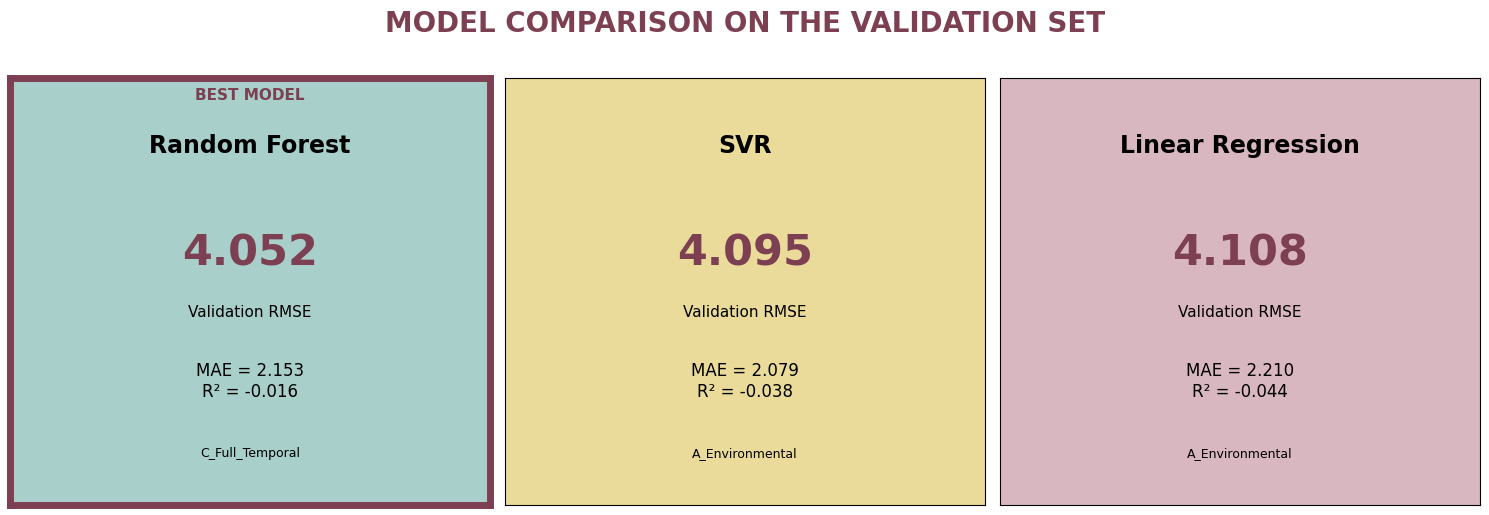

In [ ]:
# ============================================================
# DISPLAY 2 — MODEL SCORE CARDS
# ============================================================

model_colors = {
    "Linear Regression": "#d9b7c1",
    "Random Forest": "#a8cfca",
    "SVR": "#eadb9b"
}

best_core_rmse = best_core_results[
    "RMSE_original"
].min()


fig, axes = plt.subplots(
    1,
    3,
    figsize=(15, 5)
)

for axis, (_, row) in zip(
    axes,
    best_core_results.iterrows()
):

    model_name = row["Model"]
    rmse_value = row["RMSE_original"]
    mae_value = row["MAE_original"]
    r2_value = row["R2_original"]
    feature_set = row["Feature_set"]

    axis.set_facecolor(
        model_colors.get(
            model_name,
            "#dddddd"
        )
    )

    # Highlight the winner
    if np.isclose(rmse_value, best_core_rmse):
        for spine in axis.spines.values():
            spine.set_color("#7d4052")
            spine.set_linewidth(5)

        winner_text = "BEST MODEL"
    else:
        winner_text = ""

    axis.text(
        0.5,
        0.84,
        model_name,
        ha="center",
        va="center",
        fontsize=17,
        fontweight="bold",
        transform=axis.transAxes
    )

    axis.text(
        0.5,
        0.59,
        f"{rmse_value:.3f}",
        ha="center",
        va="center",
        fontsize=31,
        fontweight="bold",
        color="#7d4052",
        transform=axis.transAxes
    )

    axis.text(
        0.5,
        0.45,
        "Validation RMSE",
        ha="center",
        va="center",
        fontsize=11,
        transform=axis.transAxes
    )

    axis.text(
        0.5,
        0.29,
        f"MAE = {mae_value:.3f}\nR² = {r2_value:.3f}",
        ha="center",
        va="center",
        fontsize=12,
        transform=axis.transAxes
    )

    axis.text(
        0.5,
        0.12,
        feature_set,
        ha="center",
        va="center",
        fontsize=9,
        transform=axis.transAxes
    )

    axis.text(
        0.5,
        0.96,
        winner_text,
        ha="center",
        va="center",
        fontsize=11,
        fontweight="bold",
        color="#7d4052",
        transform=axis.transAxes
    )

    axis.set_xticks([])
    axis.set_yticks([])


fig.suptitle(
    "MODEL COMPARISON ON THE VALIDATION SET",
    fontsize=20,
    fontweight="bold",
    color="#7d4052",
    y=1.02
)

plt.tight_layout()

plt.savefig(
    "Step7_Model_Score_Cards.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

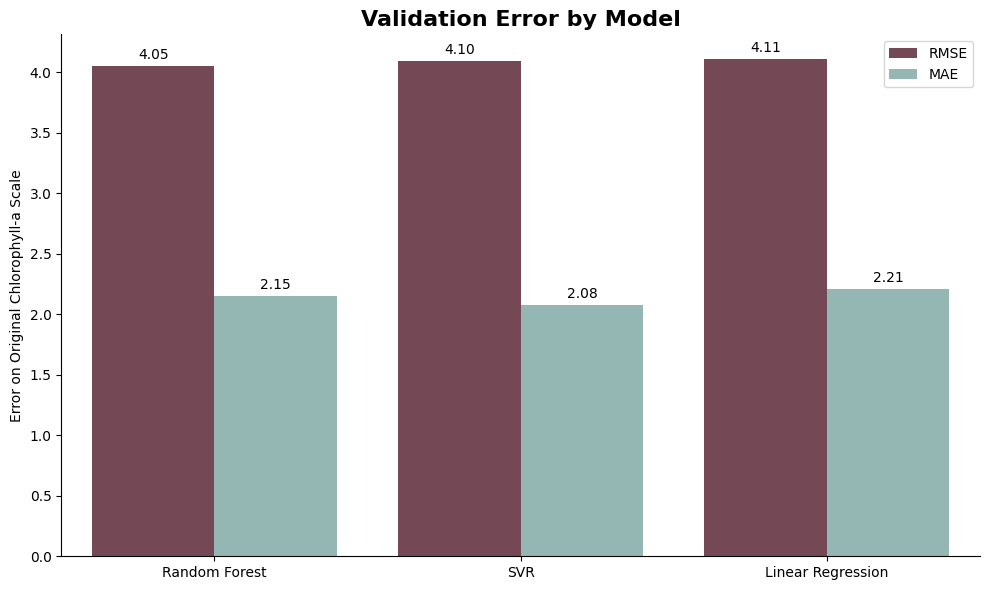

In [ ]:
# ============================================================
# DISPLAY 3 — RMSE AND MAE COMPARISON
# ============================================================

metric_plot_data = best_core_results[
    [
        "Model",
        "RMSE_original",
        "MAE_original"
    ]
].melt(
    id_vars="Model",
    var_name="Metric",
    value_name="Score"
)

metric_plot_data["Metric"] = (
    metric_plot_data["Metric"].replace({
        "RMSE_original": "RMSE",
        "MAE_original": "MAE"
    })
)


plt.figure(figsize=(10, 6))

axis = sns.barplot(
    data=metric_plot_data,
    x="Model",
    y="Score",
    hue="Metric",
    palette={
        "RMSE": "#7d4052",
        "MAE": "#8ebdb8"
    }
)

plt.title(
    "Validation Error by Model",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("")
plt.ylabel(
    "Error on Original Chlorophyll-a Scale"
)

plt.legend(title="")

for container in axis.containers:
    axis.bar_label(
        container,
        fmt="%.2f",
        padding=3
    )

sns.despine()
plt.tight_layout()

plt.savefig(
    "Step7_RMSE_MAE_Comparison.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

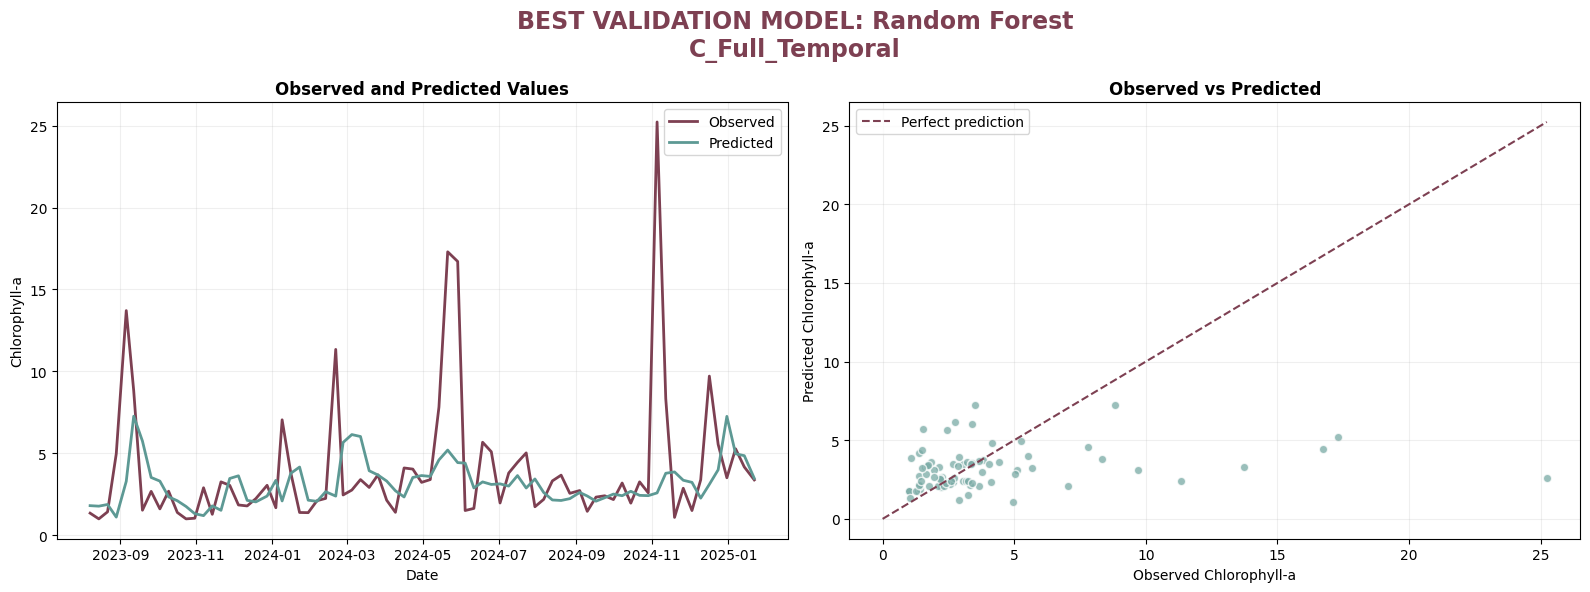

In [ ]:
# ============================================================
# DISPLAY 4 — BEST MODEL: OBSERVED VS PREDICTED
# ============================================================

# Best model among the three proposal models
best_core_row = best_core_results.iloc[0]

best_core_key = best_core_row["Model_key"]
best_core_information = trained_models[
    best_core_key
]

best_core_prediction_log = (
    best_core_information[
        "validation_prediction_log"
    ]
)

actual_validation = (
    convert_log_prediction_to_original(
        y_validation
    )
)

predicted_validation = (
    convert_log_prediction_to_original(
        best_core_prediction_log
    )
)


validation_prediction_table = pd.DataFrame({
    "time": pd.to_datetime(
        validation_df["time"]
    ),
    "Observed": actual_validation,
    "Predicted": predicted_validation
})


fig, axes = plt.subplots(
    1,
    2,
    figsize=(16, 6)
)


# Time-series plot
axes[0].plot(
    validation_prediction_table["time"],
    validation_prediction_table["Observed"],
    label="Observed",
    color="#7d4052",
    linewidth=2
)

axes[0].plot(
    validation_prediction_table["time"],
    validation_prediction_table["Predicted"],
    label="Predicted",
    color="#5d9994",
    linewidth=2
)

axes[0].set_title(
    "Observed and Predicted Values",
    fontweight="bold"
)

axes[0].set_xlabel("Date")
axes[0].set_ylabel("Chlorophyll-a")
axes[0].legend()
axes[0].grid(alpha=0.2)


# Scatter plot
axes[1].scatter(
    validation_prediction_table["Observed"],
    validation_prediction_table["Predicted"],
    color="#79aaa5",
    alpha=0.75,
    edgecolor="white"
)

maximum_value = max(
    validation_prediction_table["Observed"].max(),
    validation_prediction_table["Predicted"].max()
)

axes[1].plot(
    [0, maximum_value],
    [0, maximum_value],
    linestyle="--",
    color="#7d4052",
    label="Perfect prediction"
)

axes[1].set_title(
    "Observed vs Predicted",
    fontweight="bold"
)

axes[1].set_xlabel("Observed Chlorophyll-a")
axes[1].set_ylabel("Predicted Chlorophyll-a")
axes[1].legend()
axes[1].grid(alpha=0.2)


fig.suptitle(
    f"BEST VALIDATION MODEL: "
    f"{best_core_row['Model']}\n"
    f"{best_core_row['Feature_set']}",
    fontsize=17,
    fontweight="bold",
    color="#7d4052"
)

plt.tight_layout()

plt.savefig(
    "Step7_Best_Model_Validation.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

In [ ]:
training_results_df.to_csv("outputs/training_results.csv", index=False)
print("Saved outputs/training_results.csv")

In [ ]:
# Save every data object from this step so the next step can load it
import joblib
skip = {"In", "Out", "exit", "quit", "get_ipython", "drive", "files"}
saved = {}
for name, value in list(globals().items()):
    if name.startswith("_") or name in skip or callable(value) or type(value).__name__ == "module":
        continue
    try:
        joblib.dump(value, os.devnull)
        saved[name] = value
    except Exception:
        pass
joblib.dump(saved, "outputs/step3_models.joblib")
print("Saved outputs/step3_models.joblib with", len(saved), "objects")